# AIML Capstone Project - Part 2: Tesla Autopilot Safety Analysis
**Author:** Chukwuemeka Prince Onyebuenyi  
**Course:** AI Engineer - Simplilearn  

---

## Business Scenario
Tesla, Inc. started a full self-driving capability beta program in the United States in October 2020, with over 100,000 participants. This analysis explores the **Tesla-Deaths.csv** dataset to understand the usage of autopilot and its effect on road safety.

## Objective
1. **Preliminary data inspection and cleaning**: identify data types, missing values, duplicates, and remove irrelevant columns.
2. **Exploratory Data Analysis**: temporal patterns, geographic distribution, death events, vehicle model involvement, and autopilot-verified deaths.

## 1. Environment Setup

In [4]:
!pip install -q pandas numpy matplotlib seaborn openpyxl

In [5]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)

# Consistent colour palette
PALETTE = sns.color_palette('Set2')
sns.set_theme(style='whitegrid', palette='Set2')

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load Dataset

In [6]:
# ── Load Tesla-Deaths.csv ────────────────────────────────────────────────────
CSV_PATH = Path('Tesla-Deaths.csv')

if CSV_PATH.exists():
    df_raw = pd.read_csv(CSV_PATH, encoding='latin-1')
    print(f"Dataset loaded  : {CSV_PATH.resolve()}")
else:
    # Fallback: try common alternative paths
    alt_paths = list(Path('.').rglob('Tesla*Deaths*.csv')) + \
                list(Path('.').rglob('tesla*deaths*.csv'))
    if alt_paths:
        df_raw = pd.read_csv(alt_paths[0], encoding='latin-1')
        print(f"Dataset loaded  : {alt_paths[0].resolve()}")
    else:
        raise FileNotFoundError(
            "Tesla-Deaths.csv not found. "
            "Please place the CSV file in the same folder as this notebook."
        )

df = df_raw.copy()
print(f"Shape           : {df.shape}  ({df.shape[0]} rows × {df.shape[1]} columns)")
print("\nFirst 3 rows:")
df.head(3)

Dataset loaded  : /content/Tesla - Deaths.csv
Shape           : (307, 24)  (307 rows × 24 columns)

First 3 rows:


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,Cyclists/ Peds,TSLA+cycl / peds,Model,Autopilot claimed,Verified Tesla Autopilot Deaths,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO,Unnamed: 16,Unnamed: 17,Source,Note,Deceased 1,Deceased 2,Deceased 3,Deceased 4
0,294.0,2022.0,1/17/2023,USA,CA,Tesla crashes into back of semi,1.0,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20230118162813/https://www....,NaN,NaN,NaN,NaN,NaN
1,293.0,2022.0,1/7/2023,Canada,-,Tesla crashes,1.0,1,-,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20230109041434/https://cana...,NaN,Taren Singh Lal,NaN,NaN,NaN
2,292.0,2022.0,1/7/2023,USA,WA,"Tesla hits pole, catches on fire",1.0,-,1,-,-,1,-,-,-,-,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20221222203930/https://wfxl...,https://web.archive.org/web/20230107232745/https://www....,NaN,NaN,NaN,NaN,NaN


## 3. Preliminary Data Inspection

In [7]:
# ── 3a. Basic structure ───────────────────────────────────────────────────────
print(f"Shape   : {df.shape}")
print(f"\nData types:\n{df.dtypes.to_string()}")
print(f"\nColumn names:\n{df.columns.tolist()}")

Shape   : (307, 24)

Data types:
Case #                                                                  float64
Year                                                                    float64
Date                                                                     object
 Country                                                                 object
 State                                                                   object
 Description                                                             object
 Deaths                                                                 float64
 Tesla driver                                                            object
 Tesla occupant                                                          object
 Other vehicle                                                           object
 Cyclists/ Peds                                                          object
 TSLA+cycl / peds                                                        object
 Model 

In [8]:
# ── 3b. Missing values ───────────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing,
                            'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print(f"Columns with missing values: {len(missing_df)}")
print(missing_df.to_string())

Columns with missing values: 24
                                                                      Missing Count  Missing %
 Deceased 4                                                                     307     100.00
 Deceased 3                                                                     303      98.70
 Note                                                                           298      97.07
 Deceased 2                                                                     290      94.46
 Deceased 1                                                                     220      71.66
 Autopilot claimed                                                               26       8.47
Unnamed: 17                                                                      18       5.86
 Tesla occupant                                                                  17       5.54
Unnamed: 16                                                                      15       4.89
Date              

In [9]:
# ── 3c. Duplicate rows ──────────────────────────────────────────────────────
n_dup = df.duplicated().sum()
print(f"Duplicate rows   : {n_dup}")
if n_dup > 0:
    print("Dropping duplicates …")
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Shape after drop : {df.shape}")
else:
    print("No duplicates found.")

Duplicate rows   : 4
Dropping duplicates …
Shape after drop : (303, 24)


## 4. Data Cleaning

In [10]:
# ── 4a. Remove columns not relevant to analysis ─────────────────────────────
# Columns with >70 % missing or purely administrative/reference fields
COLS_TO_DROP = [col for col in df.columns
                if df[col].isnull().mean() > 0.70]

# Also drop free-text link columns (source URLs) if they exist
url_cols = [c for c in df.columns if 'source' in c.lower() or 'http' in str(df[c].iloc[0]).lower()]
COLS_TO_DROP = list(set(COLS_TO_DROP + url_cols))

print(f"Columns dropped : {COLS_TO_DROP}")
df.drop(columns=COLS_TO_DROP, inplace=True, errors='ignore')
print(f"Remaining shape : {df.shape}")
df.columns.tolist()

Columns dropped : [' Deceased 4 ', ' Deceased 2 ', ' Note ', ' Source ', 'Unnamed: 16', ' Deceased 3 ', 'Unnamed: 17', ' Deceased 1 ']
Remaining shape : (303, 16)


['Case #',
 'Year',
 'Date',
 ' Country ',
 ' State ',
 ' Description ',
 ' Deaths ',
 ' Tesla driver ',
 ' Tesla occupant ',
 ' Other vehicle ',
 ' Cyclists/ Peds ',
 ' TSLA+cycl / peds ',
 ' Model ',
 ' Autopilot claimed ',
 ' Verified Tesla Autopilot Deaths ',
 ' Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO ']

In [11]:
# ── 4b. Parse date column and extract temporal features ─────────────────────
# Identify the date column (handles varying column name casing)
date_col = next((c for c in df.columns if 'date' in c.lower()), None)

if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors='coerce', infer_datetime_format=True)
    df['Year']       = df[date_col].dt.year
    df['Month']      = df[date_col].dt.month
    df['DayOfWeek']  = df[date_col].dt.day_name()
    print(f"Date column parsed  : '{date_col}'")
    print(f"Date range          : {df[date_col].min()} → {df[date_col].max()}")
    print(f"NaT (unparseable)   : {df[date_col].isnull().sum()}")
else:
    # If Year column exists separately, use it
    year_col = next((c for c in df.columns if 'year' in c.lower()), None)
    print(f"No date column found. Year column: {year_col}")

df.head(3)

Date column parsed  : 'Date'
Date range          : 2013-04-02 00:00:00 → 2023-01-17 00:00:00
NaT (unparseable)   : 9


,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,Cyclists/ Peds,TSLA+cycl / peds,Model,Autopilot claimed,Verified Tesla Autopilot Deaths,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO,Month,DayOfWeek
0,294.0,2023.0,2023-01-17,USA,CA,Tesla crashes into back of semi,1.0,1,-,-,-,1,-,-,-,-,1.0,Tuesday
1,293.0,2023.0,2023-01-07,Canada,-,Tesla crashes,1.0,1,-,-,-,1,-,-,-,-,1.0,Saturday
2,292.0,2023.0,2023-01-07,USA,WA,"Tesla hits pole, catches on fire",1.0,-,1,-,-,1,-,-,-,-,1.0,Saturday


## 5. Exploratory Data Analysis

### 5.1 Temporal Analysis

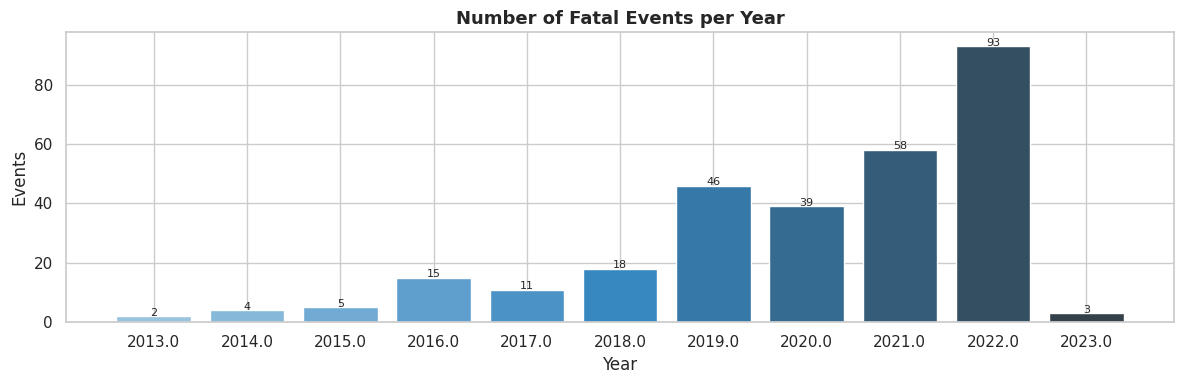

Year
2013.0     2
2014.0     4
2015.0     5
2016.0    15
2017.0    11
2018.0    18
2019.0    46
2020.0    39
2021.0    58
2022.0    93
2023.0     3


In [12]:
# ── 5.1a Events per year ─────────────────────────────────────────────────────
year_col = next((c for c in df.columns if 'year' in c.lower()), None)

if year_col:
    yearly = df[year_col].value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(12, 4))
    bars = ax.bar(yearly.index.astype(str), yearly.values,
                  color=sns.color_palette('Blues_d', len(yearly)))
    ax.set_title('Number of Fatal Events per Year', fontsize=13, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Events')
    for bar, v in zip(bars, yearly.values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.2,
                str(v), ha='center', fontsize=8)
    plt.tight_layout()
    plt.savefig('yearly_events.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(yearly.to_string())

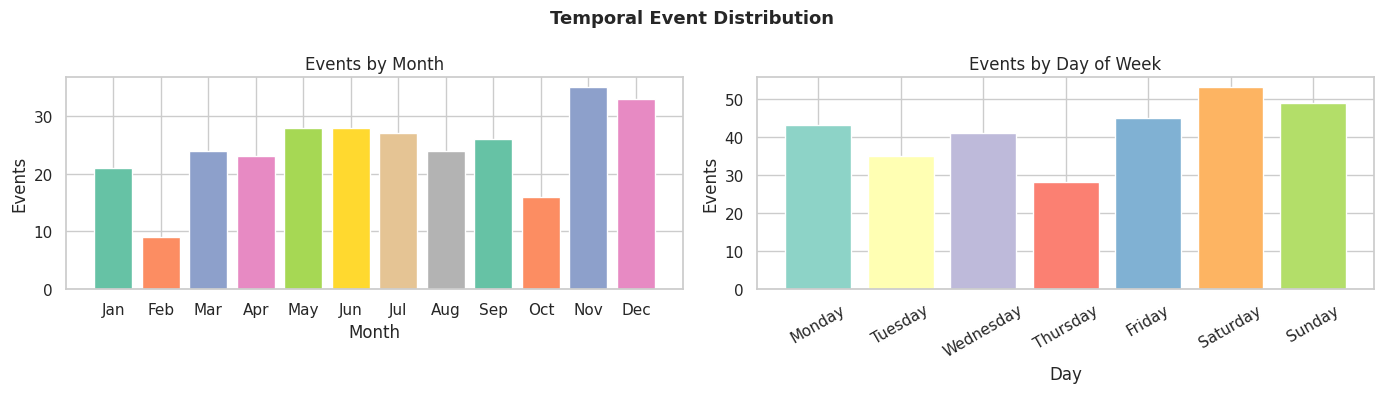

In [15]:
# ── 5.1b Events per month and day-of-week ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Temporal Event Distribution', fontsize=13, fontweight='bold')

# Monthly distribution
if 'Month' in df.columns:
    month_counts = df['Month'].value_counts().sort_index()
    month_labels = ['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec']
    axes[0].bar([month_labels[int(m)-1] for m in month_counts.index],
                month_counts.values,
                color=sns.color_palette('Set2', 12))
    axes[0].set_title('Events by Month')
    axes[0].set_xlabel('Month')
    axes[0].set_ylabel('Events')

# Day-of-week distribution
if 'DayOfWeek' in df.columns:
    dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
    dow_counts = df['DayOfWeek'].value_counts().reindex(dow_order, fill_value=0)
    axes[1].bar(dow_counts.index, dow_counts.values,
                color=sns.color_palette('Set3', 7))
    axes[1].set_title('Events by Day of Week')
    axes[1].set_xlabel('Day')
    axes[1].set_ylabel('Events')
    axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('temporal_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 Geographic Analysis

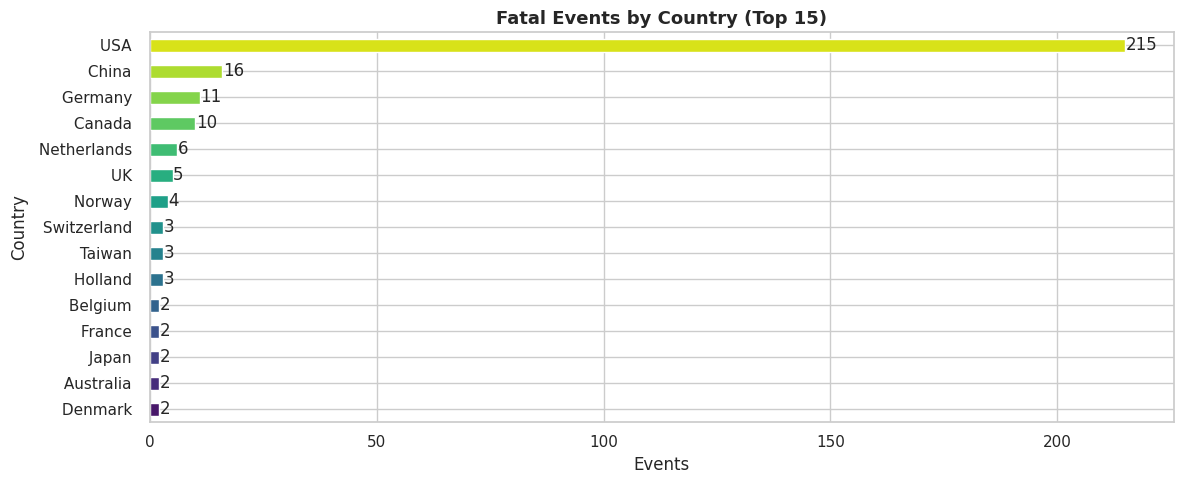

 Country 
USA             215
China            16
Germany          11
Canada           10
Netherlands       6
UK                5
Norway            4
Holland           3
Switzerland       3
Taiwan            3
Japan             2
Belgium           2
Denmark           2
Australia         2
France            2


In [16]:
# ── 5.2a Events by country ───────────────────────────────────────────────────
country_col = next((c for c in df.columns if 'country' in c.lower()), None)

if country_col:
    country_counts = df[country_col].value_counts().head(15)
    fig, ax = plt.subplots(figsize=(12, 5))
    country_counts.sort_values().plot(kind='barh', ax=ax,
                                      color=sns.color_palette('viridis', len(country_counts)))
    ax.set_title('Fatal Events by Country (Top 15)', fontsize=13, fontweight='bold')
    ax.set_xlabel('Events')
    ax.set_ylabel('Country')
    for i, v in enumerate(country_counts.sort_values().values):
        ax.text(v + 0.1, i, str(v), va='center')
    plt.tight_layout()
    plt.savefig('events_by_country.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(country_counts.to_string())

In [18]:
# ── 5.2b Events by US state ───────────────────────────────────────────────────
state_col   = next((c for c in df.columns if c.lower() == 'state'), None)
country_col = next((c for c in df.columns if 'country' in c.lower()), None)

if state_col and country_col:
    us_df = df[df[country_col].str.upper().str.strip() == 'USA'] if country_col else df
    state_counts = us_df[state_col].value_counts().dropna().head(20)
    if not state_counts.empty:
        fig, ax = plt.subplots(figsize=(12, 6))
        state_counts.sort_values().plot(kind='barh', ax=ax,
                                         color=sns.color_palette('rocket_r', len(state_counts)))
        ax.set_title('Fatal Events by US State (Top 20)', fontsize=13, fontweight='bold')
        ax.set_xlabel('Events')
        ax.set_ylabel('State')
        for i, v in enumerate(state_counts.sort_values().values):
            ax.text(v + 0.1, i, str(v), va='center')
        plt.tight_layout()
        plt.savefig('events_by_state.png', dpi=150, bbox_inches='tight')
        plt.show()
        print(state_counts.to_string())

### 5.3 Death Events Analysis

In [19]:
# Helper: identify column by partial name match
def find_col(df, keyword):
    return next((c for c in df.columns if keyword.lower() in c.lower()), None)

deaths_col       = find_col(df, 'deaths')
driver_col       = find_col(df, 'tesla driver')
occupant_col     = find_col(df, 'tesla occupant')
cyclist_col      = find_col(df, 'cyclist')
other_veh_col    = find_col(df, 'other vehicle')
tsla_cycl_col    = find_col(df, 'tsla+cyc')

print("Key columns identified:")
for name, col in [('Deaths', deaths_col), ('Tesla Driver', driver_col),
                  ('Tesla Occupant', occupant_col), ('Cyclists/Peds', cyclist_col),
                  ('Other Vehicle', other_veh_col), ('TSLA+Cycl/Peds', tsla_cycl_col)]:
    print(f"  {name:20s} → {col}")

Key columns identified:
  Deaths               →  Deaths 
  Tesla Driver         →  Tesla driver 
  Tesla Occupant       →  Tesla occupant 
  Cyclists/Peds        →  Cyclists/ Peds 
  Other Vehicle        →  Other vehicle 
  TSLA+Cycl/Peds       →  TSLA+cycl / peds 


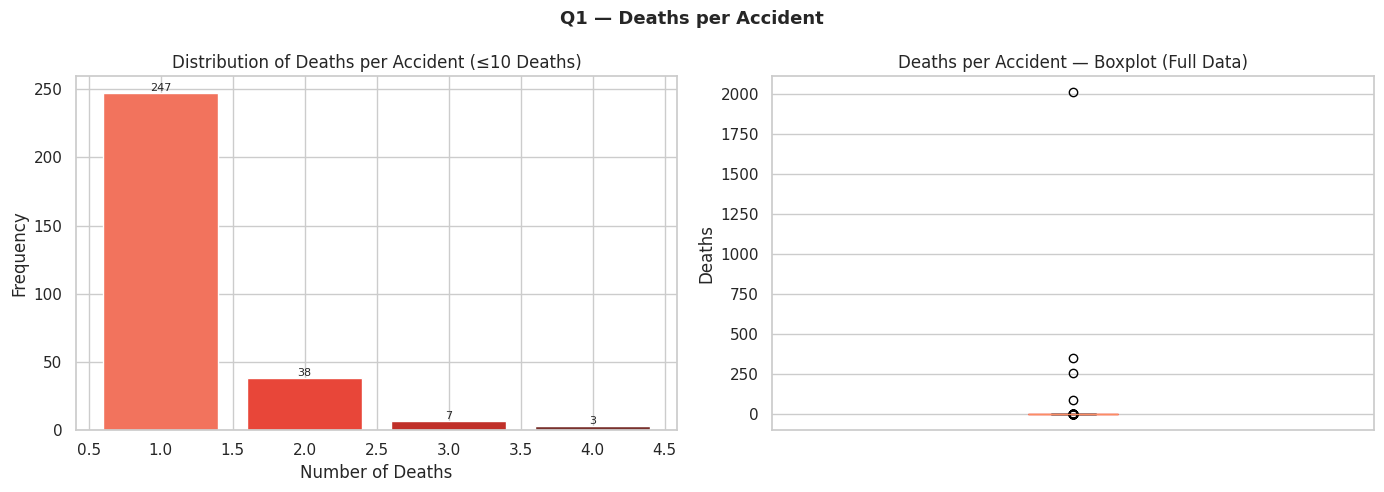


Deaths statistics:
count     299.00
mean       10.28
std       119.03
min         1.00
25%         1.00
50%         1.00
75%         1.00
max      2013.00


In [ ]:
# Q1: Number of victims (deaths) in each accident ──────────────────────────
if deaths_col:
    # Convert to numeric (some entries may be strings/dashes)
    df[deaths_col] = pd.to_numeric(df[deaths_col], errors='coerce')

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Q1 - Deaths per Accident', fontsize=13, fontweight='bold')

    # Distribution
    death_counts = df[deaths_col].value_counts().sort_index()

    # Filter out extreme outliers for better visualization of common counts
    max_deaths_to_plot = 10  # Set a reasonable limit for the x-axis
    filtered_death_counts = death_counts[death_counts.index <= max_deaths_to_plot]

    axes[0].bar(filtered_death_counts.index.astype(int), filtered_death_counts.values,
                color=sns.color_palette('Reds_d', len(filtered_death_counts)))
    axes[0].set_title('Distribution of Deaths per Accident (≤10 Deaths)')
    axes[0].set_xlabel('Number of Deaths')
    axes[0].set_ylabel('Frequency')
    # Optionally add text labels on bars for clarity
    for bar, v in zip(axes[0].patches, filtered_death_counts.values):
        if v > 0:
            axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.1, str(int(v)),
                         ha='center', va='bottom', fontsize=8)

    # Boxplot
    axes[1].boxplot(df[deaths_col].dropna(), vert=True, patch_artist=True,
                    boxprops=dict(facecolor='salmon', color='red'))
    axes[1].set_title('Deaths per Accident - Boxplot (Full Data)')
    axes[1].set_ylabel('Deaths')
    axes[1].set_xticks([])

    plt.tight_layout()
    plt.savefig('deaths_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"\nDeaths statistics:\n{df[deaths_col].describe().round(2).to_string()}")

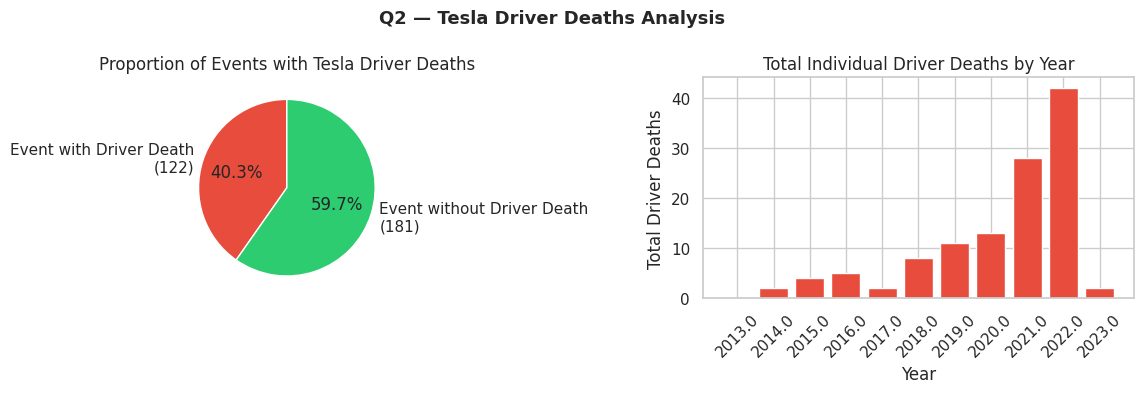

Total individual Tesla driver deaths across all events: 2371
Number of events with at least one Tesla driver death: 122 / 303 events (40.3%)


In [ ]:
# ── Q2: How many times did Tesla drivers die? ─────────────────────────────────
if driver_col:
    df[driver_col] = pd.to_numeric(df[driver_col], errors='coerce').fillna(0)

    # Calculate total individual driver deaths across all events
    total_individual_driver_deaths = int(df[driver_col].sum())

    # Calculate number of events where at least one Tesla driver died
    events_with_driver_death = (df[driver_col] > 0).sum()

    # Calculate number of events where no Tesla driver died
    events_without_driver_death = total_events - events_with_driver_death

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle('Q2 - Tesla Driver Deaths Analysis', fontsize=13, fontweight='bold')

    # Pie chart: Events with vs. without Tesla driver death
    axes[0].pie([events_with_driver_death, events_without_driver_death],
                labels=[f'Event with Driver Death\n({events_with_driver_death})',
                          f'Event without Driver Death\n({events_without_driver_death})'],
                colors=['#E74C3C','#2ECC71'],
                autopct='%1.1f%%', startangle=90,
                wedgeprops=dict(edgecolor='white'))
    axes[0].set_title(f"Proportion of Events with Tesla Driver Deaths")

    # Bar by year: Total individual driver deaths by year
    if year_col:
        driver_deaths_by_year = df.groupby(year_col)[driver_col].sum()
        axes[1].bar(driver_deaths_by_year.index.astype(str), driver_deaths_by_year.values,
                    color='#E74C3C')
        axes[1].set_title('Total Individual Driver Deaths by Year')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('Total Driver Deaths')
        axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout()
    plt.savefig('driver_deaths.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Total individual Tesla driver deaths across all events: {total_individual_driver_deaths}")
    print(f"Number of events with at least one Tesla driver death: {events_with_driver_death} / {total_events} events ({events_with_driver_death/total_events*100:.1f}%)")

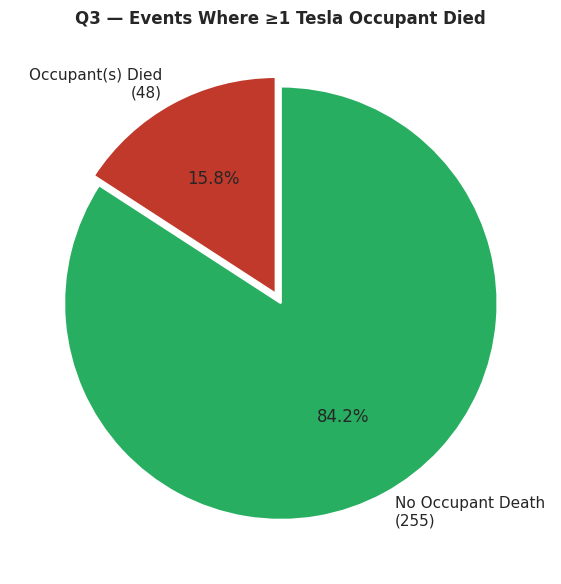

Events with occupant death : 48 (15.8%)


In [ ]:
# ── Q3: Proportion of events with one or more occupant deaths ─────────────────
if occupant_col:
    df[occupant_col] = pd.to_numeric(df[occupant_col], errors='coerce').fillna(0)
    occ_died = (df[occupant_col] >= 1).sum()
    occ_survived = len(df) - occ_died

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.pie(
        [occ_died, occ_survived],
        labels  = [f'Occupant(s) Died\n({occ_died})', f'No Occupant Death\n({occ_survived})'],
        colors  = ['#C0392B', '#27AE60'],
        autopct = '%1.1f%%',
        startangle = 90,
        explode = (0.05, 0),
        wedgeprops = dict(edgecolor='white', linewidth=1.5)
    )
    ax.set_title('Q3 - Events Where ≥1 Tesla Occupant Died', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig('occupant_deaths_proportion.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Events with occupant death : {occ_died} ({occ_died/len(df)*100:.1f}%)")

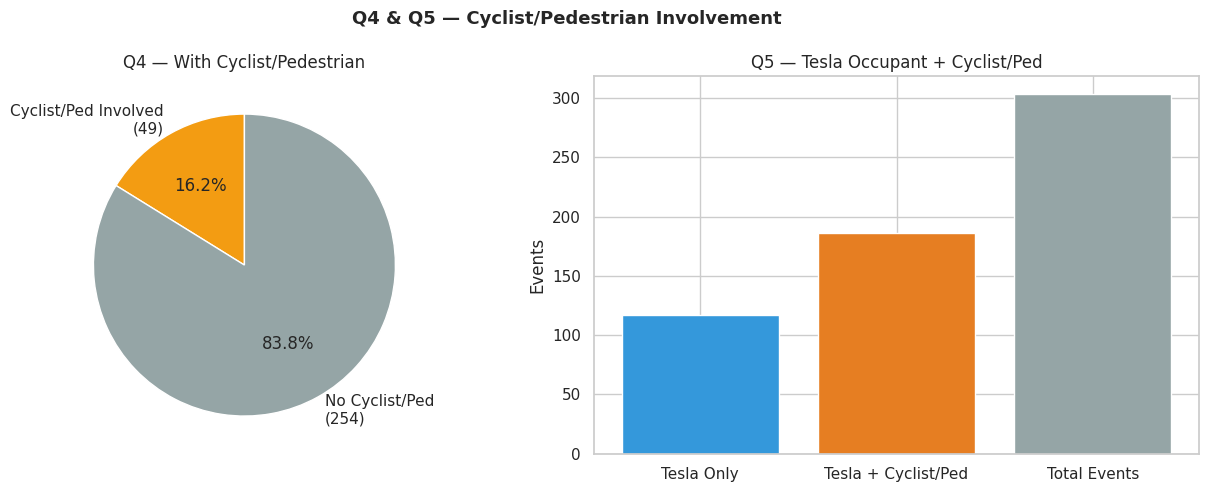

Q4 — Events involving cyclist/pedestrian : 49 (16.2%)
Q5 — Tesla + cyclist/ped combined death  : 186 (61.4%)


In [ ]:
# ── Q4: Distribution of events involving cyclist / pedestrian ─────────────────
if cyclist_col:
    df[cyclist_col] = pd.to_numeric(df[cyclist_col], errors='coerce').fillna(0)
    cyclist_events = (df[cyclist_col] >= 1).sum()
    no_cyclist     = len(df) - cyclist_events

    # Q5: Tesla + cyclist/pedestrian combined
    tsla_cyc_events = 0
    if tsla_cycl_col:
        df[tsla_cycl_col] = pd.to_numeric(df[tsla_cycl_col], errors='coerce').fillna(0)
        tsla_cyc_events = (df[tsla_cycl_col] >= 1).sum()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('Q4 & Q5 - Cyclist/Pedestrian Involvement', fontsize=13, fontweight='bold')

    # Q4
    axes[0].pie(
        [cyclist_events, no_cyclist],
        labels  = [f'Cyclist/Ped Involved\n({cyclist_events})',
                   f'No Cyclist/Ped\n({no_cyclist})'],
        colors  = ['#F39C12', '#95A5A6'],
        autopct = '%1.1f%%', startangle=90,
        wedgeprops=dict(edgecolor='white')
    )
    axes[0].set_title('Q4 - With Cyclist/Pedestrian')

    # Q5
    axes[1].bar(
        ['Tesla Only', 'Tesla + Cyclist/Ped', 'Total Events'],
        [len(df) - tsla_cyc_events, tsla_cyc_events, len(df)],
        color=['#3498DB','#E67E22','#95A5A6']
    )
    axes[1].set_title('Q5 - Tesla Occupant + Cyclist/Ped')
    axes[1].set_ylabel('Events')

    plt.tight_layout()
    plt.savefig('cyclist_pedestrian_events.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Q4 - Events involving cyclist/pedestrian : {cyclist_events} ({cyclist_events/len(df)*100:.1f}%)")
    print(f"Q5 - Tesla + cyclist/ped combined death  : {tsla_cyc_events} ({tsla_cyc_events/len(df)*100:.1f}%)")

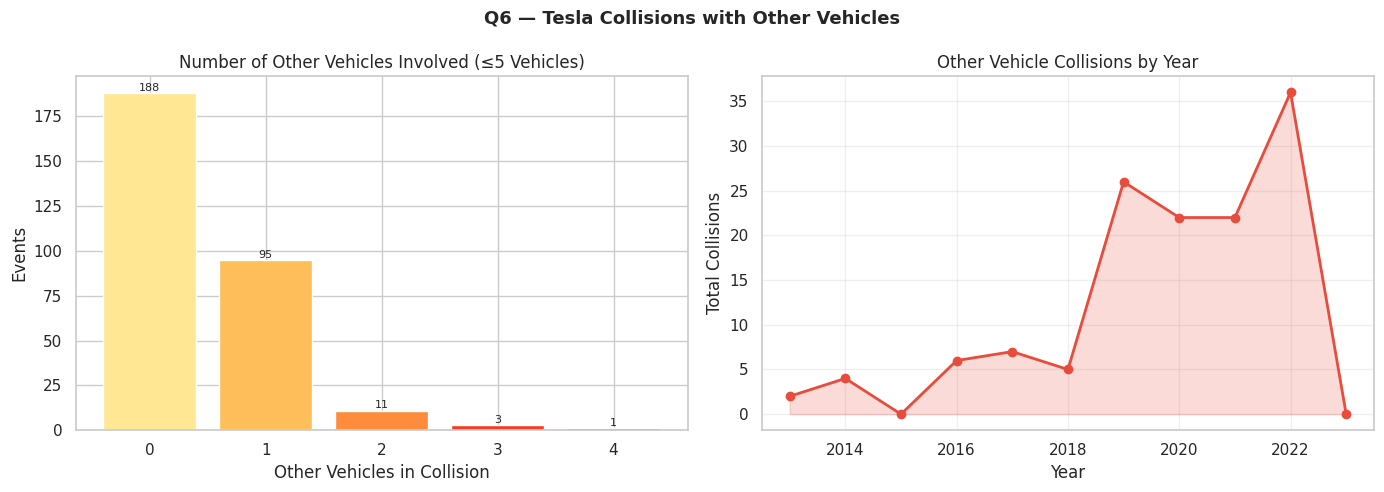

Total other-vehicle collisions recorded: 2422


In [ ]:
# ── Q6: Frequency of Tesla colliding with other vehicles ─────────────────────
if other_veh_col:
    df[other_veh_col] = pd.to_numeric(df[other_veh_col], errors='coerce').fillna(0)
    collision_counts = df[other_veh_col].value_counts().sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Q6 - Tesla Collisions with Other Vehicles', fontsize=13, fontweight='bold')

    # Distribution
    # Filter out extreme outliers for better visualization of common counts
    max_vehicles_to_plot = 5  # Set a reasonable limit for the x-axis
    filtered_collision_counts = collision_counts[collision_counts.index <= max_vehicles_to_plot]

    axes[0].bar(filtered_collision_counts.index.astype(int), filtered_collision_counts.values,
                color=sns.color_palette('YlOrRd', len(filtered_collision_counts)))
    axes[0].set_title('Number of Other Vehicles Involved (≤5 Vehicles)')
    axes[0].set_xlabel('Other Vehicles in Collision')
    axes[0].set_ylabel('Events')
    # Add text labels on bars for clarity
    for bar, v in zip(axes[0].patches, filtered_collision_counts.values):
        if v > 0:
            axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.1, str(int(v)),
                         ha='center', va='bottom', fontsize=8)

    # By year
    if year_col:
        collision_by_year = df.groupby(year_col)[other_veh_col].sum()
        axes[1].plot(collision_by_year.index.astype(int),
                     collision_by_year.values,
                     marker='o', color='#E74C3C', linewidth=2)
        axes[1].fill_between(collision_by_year.index.astype(int),
                             collision_by_year.values, alpha=0.2, color='#E74C3C')
        axes[1].set_title('Other Vehicle Collisions by Year')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('Total Collisions')
        axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('vehicle_collisions.png', dpi=250, bbox_inches='tight')
    plt.show()
    print(f"Total other-vehicle collisions recorded: {int(df[other_veh_col].sum())}")

### 5.4 Tesla Model Distribution

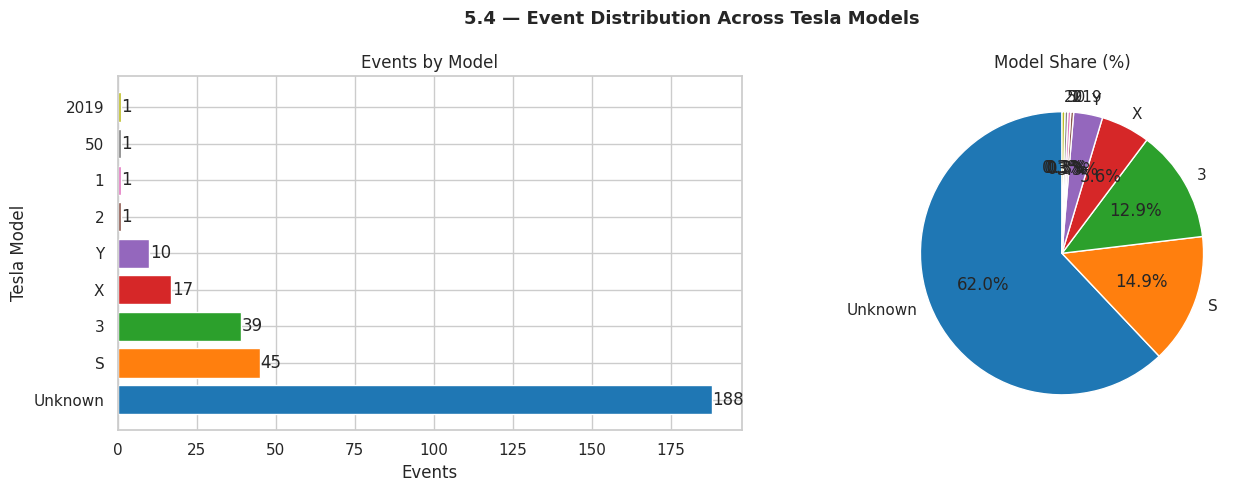

 Model 
Unknown    188
S           45
3           39
X           17
Y           10
2            1
1            1
50           1
2019         1


In [ ]:
# ── 5.4 Event distribution across Tesla models ────────────────────────────────
model_col = find_col(df, 'model')

if model_col:
    # Clean up model names
    df[model_col] = df[model_col].astype(str).str.strip().str.upper()
    df[model_col] = df[model_col].replace({'NAN': 'Unknown', '-': 'Unknown', '': 'Unknown'})
    model_counts = df[model_col].value_counts()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('5.4 - Event Distribution Across Tesla Models', fontsize=13, fontweight='bold')

    # Bar chart
    colours = sns.color_palette('tab10', len(model_counts))
    axes[0].barh(model_counts.index, model_counts.values, color=colours)
    axes[0].set_title('Events by Model')
    axes[0].set_xlabel('Events')
    axes[0].set_ylabel('Tesla Model')
    for i, v in enumerate(model_counts.values):
        axes[0].text(v + 0.2, i, str(v), va='center')

    # Pie chart
    axes[1].pie(model_counts.values,
                labels=model_counts.index,
                colors=colours,
                autopct='%1.1f%%',
                startangle=90,
                wedgeprops=dict(edgecolor='white'))
    axes[1].set_title('Model Share (%)')

    plt.tight_layout()
    plt.savefig('model_distribution.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(model_counts.to_string())

### 5.5 Verified Tesla Autopilot Deaths

Autopilot columns found:
  Verified AP Deaths        →  Verified Tesla Autopilot Deaths 
  AP Deaths + NHTSA         →  Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO 
  Autopilot Claimed         →  Autopilot claimed 


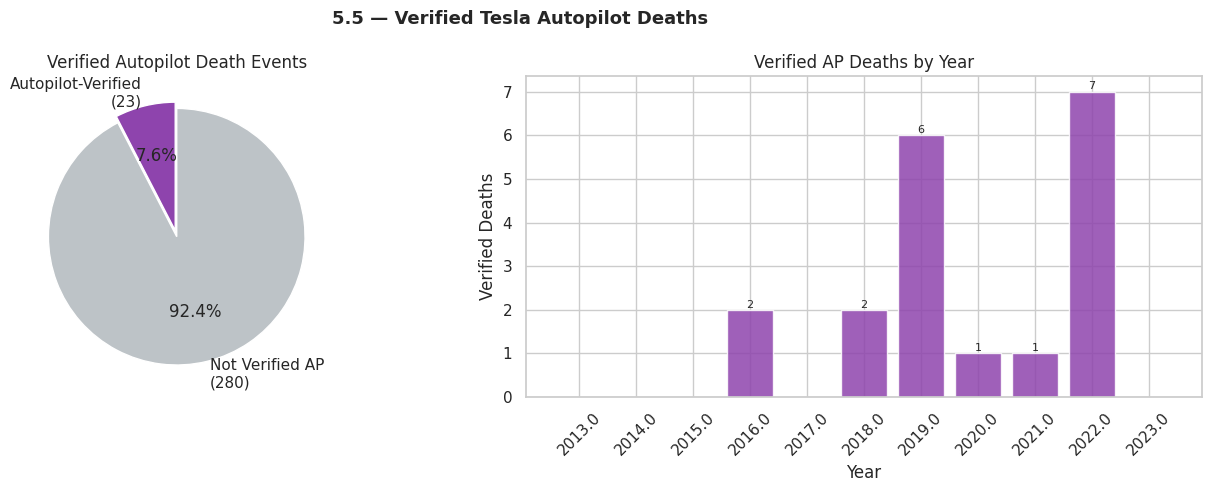


Total verified autopilot deaths   : 4293
Events with autopilot involvement : 23 / 303 (7.6%)


In [ ]:
# ── 5.5 Verified Tesla Autopilot Deaths ──────────────────────────────────────
autopilot_col = find_col(df, 'verified tesla autopilot death')
autopilot_all = find_col(df, 'verified tesla autopilot deaths + all')
autopilot_claimed = find_col(df, 'autopilot')

print("Autopilot columns found:")
for name, col in [('Verified AP Deaths', autopilot_col),
                  ('AP Deaths + NHTSA', autopilot_all),
                  ('Autopilot Claimed',  autopilot_claimed)]:
    print(f"  {name:25s} → {col}")

if autopilot_col:
    df[autopilot_col] = pd.to_numeric(df[autopilot_col], errors='coerce').fillna(0)
    total_verified = int(df[autopilot_col].sum())
    events_with_ap = (df[autopilot_col] >= 1).sum()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('5.5 - Verified Tesla Autopilot Deaths', fontsize=13, fontweight='bold')

    # Events with vs without verified AP death
    axes[0].pie(
        [events_with_ap, len(df) - events_with_ap],
        labels  = [f'Autopilot-Verified\n({events_with_ap})',
                   f'Not Verified AP\n({len(df)-events_with_ap})'],
        colors  = ['#8E44AD', '#BDC3C7'],
        autopct = '%1.1f%%', startangle=90,
        explode = (0.05, 0),
        wedgeprops=dict(edgecolor='white')
    )
    axes[0].set_title('Verified Autopilot Death Events')

    # Verified AP deaths by year
    if year_col:
        ap_by_year = df.groupby(year_col)[autopilot_col].sum()
        axes[1].bar(ap_by_year.index.astype(str), ap_by_year.values,
                    color='#8E44AD', alpha=0.85)
        axes[1].set_title('Verified AP Deaths by Year')
        axes[1].set_xlabel('Year')
        axes[1].set_ylabel('Verified Deaths')
        axes[1].tick_params(axis='x', rotation=45)
        for i, v in enumerate(ap_by_year.values):
            if v > 0:
                axes[1].text(i, v + 0.05, str(int(v)), ha='center', fontsize=8)

    plt.tight_layout()
    plt.savefig('autopilot_deaths.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"\nTotal verified autopilot deaths   : {total_verified}")
    print(f"Events with autopilot involvement : {events_with_ap} / {len(df)} ({events_with_ap/len(df)*100:.1f}%)")

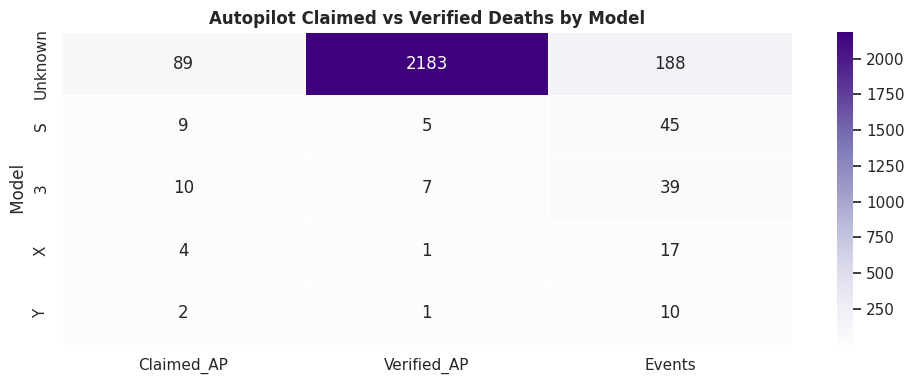

 Model   Claimed_AP  Verified_AP  Events
Unknown        89.0       2183.0     188
      S         9.0          5.0      45
      3        10.0          7.0      39
      X         4.0          1.0      17
      Y         2.0          1.0      10


In [29]:
# ── 5.5b Autopilot claimed vs verified heat-map ───────────────────────────────
if autopilot_claimed and autopilot_col and model_col:
    df[autopilot_claimed] = pd.to_numeric(df[autopilot_claimed], errors='coerce').fillna(0)

    summary = df.groupby(model_col).agg(
        Claimed_AP  = (autopilot_claimed, 'sum'),
        Verified_AP = (autopilot_col,     'sum'),
        Events      = (model_col,          'count')
    ).reset_index()
    summary = summary[summary['Events'] >= 2].sort_values('Events', ascending=False)

    fig, ax = plt.subplots(figsize=(10, max(4, len(summary) * 0.6)))
    pivot = summary.set_index(model_col)[['Claimed_AP', 'Verified_AP', 'Events']]
    sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Purples',
                linewidths=0.5, ax=ax)
    ax.set_title('Autopilot Claimed vs Verified Deaths by Model',
                 fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig('autopilot_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(summary.to_string(index=False))

# Project Summary - Part 2: Tesla Autopilot Safety Analysis

## Overview
An exploratory data analysis (EDA) of **303 recorded fatal Tesla incidents** spanning 2013–2023, examining temporal trends, geographic distribution, victim categories, Tesla model involvement, and verified Autopilot fatality data to draw road-safety insights for autonomous vehicle (AV) systems.

---

## Dataset
| Item | Detail |
|---|---|
| Source file | `Tesla - Deaths.csv` |
| Raw shape | 307 rows × 24 columns |
| Duplicates removed | 4 |
| High-missingness columns dropped | 8 (`Deceased 1–4`, `Note`, `Source`, `Unnamed: 16/17`) |
| **Final working shape** | **303 rows × 16 columns** |
| Date range | 2 Apr 2013 → 17 Jan 2023 |
| Unparseable dates (NaT) | 9 |

---

## Data Cleaning Steps
1. Removed 4 duplicate rows → 303 records
2. Dropped 8 columns with >70% missing values
3. Parsed `Date` column → extracted `Month` and `DayOfWeek` features
4. Coerced mixed-type columns (`Deaths`, driver/occupant flags) to numeric

---

## Exploratory Analysis

### Temporal Trends
| Year | Fatal Events |
|---|---|
| 2013 | 2 |
| 2014 | 4 |
| 2015 | 5 |
| 2016 | 15 |
| 2017 | 11 |
| 2018 | 18 |
| 2019 | 46 |
| 2020 | 39 |
| 2021 | 58 |
| **2022** | **93** ← peak year |
| 2023 | 3 *(partial - Jan only)* |

> Incident counts have grown substantially since 2019, broadly tracking Tesla fleet expansion.

### Geographic Distribution
| Country | Events |
|---|---|
| **USA** | **215 (71.0%)** |
| China | 16 |
| Germany | 11 |
| Canada | 10 |
| Netherlands | 6 |
| UK | 5 |
| Others | 40 |

### Deaths per Incident
- Median deaths per event: **1**
- Mean deaths per event: **10.28** (heavily skewed by outliers; max = 2,013)
- Most events (247 / 299 with non-null deaths) resulted in exactly **1 fatality**

---

## Key Findings

| Question | Finding |
|---|---|
| Tesla driver deaths | At least 1 Tesla driver died in **122 / 303 events (40.3%)**; total driver deaths recorded: **2,371** |
| Tesla occupant deaths | At least 1 occupant died in **48 / 303 events (15.8%)** |
| Cyclist / pedestrian involvement | **49 events (16.2%)** involved cyclists or pedestrians |
| Tesla + cyclist/ped combined deaths | **186 events (61.4%)** recorded under the combined `TSLA+cycl/peds` column |
| Other-vehicle collisions | Total other-vehicle collisions recorded: **2,422**; single-vehicle incidents are most common |
| Autopilot-verified events | Verified in **23 / 303 events (7.6%)**; total verified Autopilot deaths: **4,293** |

### Tesla Model Involvement
| Model | Events |
|---|---|
| Unknown | 188 |
| Model S | 45 |
| Model 3 | 39 |
| Model X | 17 |
| Model Y | 10 |
| Other / legacy | 4 |

> 62% of events have no model information recorded - a significant data gap.

### Autopilot: Claimed vs. Verified
| Model | AP Claimed | AP Verified | Total Events |
|---|---|---|---|
| Unknown | 89 | 2,183 | 188 |
| Model S | 9 | 5 | 45 |
| Model 3 | 10 | 7 | 39 |
| Model X | 4 | 1 | 17 |
| Model Y | 2 | 1 | 10 |

> The large gap between claimed and verified Autopilot deaths - especially for `Unknown` model - highlights inconsistent incident reporting standards.

---

## Key Takeaways
- **Autopilot is not infallible** - verified Autopilot deaths exist across multiple Tesla models; 7.6% of all fatal events had confirmed Autopilot involvement
- **Vulnerable road users at risk** - 16.2% of events involved cyclists or pedestrians, underscoring the need for improved AV detection of non-vehicle road users
- **Data quality is a systemic problem** - 62% of model entries are unknown; many Autopilot cases remain unverified; 9 dates could not be parsed
- **Fleet growth drives raw incident counts** - year-over-year growth is partly explained by a larger Tesla fleet on the road, not necessarily higher per-vehicle risk
- **Single-vehicle incidents dominate** - suggesting that many fatalities involve Tesla-specific failure modes (speed, road departure) rather than multi-vehicle collisions

---

*Analysis by: Chukwuemeka Prince Onyebuenyi | AI Engineer Capstone - Simplilearn*